### Kreis-Code – Lösung Schritt für Schritt

*35. Bundeswettbewerb Informatik (2016/2017), 2. Runde, Aufgabe 3*

Damit Computer mit Text umgehen können, müssen die Zeichen geeignet codiert werden. Für die Codierung gibt es beispielsweise
Binärcodes wie den ASCII-Code. Um Zeichen auch in Bildern darzustellen, so dass sie leicht mit dem Computer gelesen werden können,
gibt es grafische Codes. Bekannt sind z.B. Strichcodes und QR-Codes, mit denen Ziffernfolgen und Texte codiert werden können.

Beim Erkennen dieser Codes muss das Lesegerät zum Code ausgerichtet werden. Grafische Codes, die auch in Fotos einfach lesbar sein
sollen, müssen aber unabhängig von ihrer Orientierung erkannt werden können. Daher führen wir den Kreis-Code ein: Ein Zeichen dieses
Codes besteht aus einem schwarzen Kreis und vier mit dem Kreis konzentrischen weißen und schwarzen Ringen. Der Durchmesser des Kreises
ist dreimal so groß wie die Breite eines Ringes. Der äußerste Ring *(in der Abbildung des Aufgabenblatts grau gezeichnet)* ist in 16
Segmente geteilt, die schwarz oder weiß sein können. Das heißt, der Ring entspricht, von oben im Uhrzeigersinn gelesen, einer Folge
von 16 Bit. Mit diesen 16 Bit lassen sich Textzeichen codieren, z.B. bedeutet 0000 1110 0110 1101 den Buchstaben A. Damit der
Kreis-Code aus jeder Blickrichtung gedeutet werden kann, sind die Codezeichen so gewählt, dass keines durch Rotation eines anderen
hervorgeht; d.h. 1001 1011 0100 0011 bedeutet auch den Buchstaben A.

In dieser Aufgabe geht es darum, Kreis-Code in Bildern zu erkennen und zu decodieren.

#### Aufgabe

1. Schreibe ein Programm, das für ein vorgegebenes Schwarz-Weiß-Bild mit mehreren Kreis-Codezeichen deren Mittelpunkte bestimmt.
2. Erweitere dein Programm so, dass es für jedes Kreis-Codezeichen im Bild dessen Bedeutung ausgibt. Eine Tabelle mit der Bedeutung
   der Codezeichen findest du auf der BWINF-Webseite zu dieser Runde.
3. Auf Fotos kann die Abbildung von Codezeichen verzerrt, unscharf, verschattet und undeutlich sein. Erweitere dein Programm so, dass
   es trotz solcher Probleme Kreis-Code in Fotos decodieren kann. Wende es auf die Beispielfotos an, die du auf der BWINF-Webseite zu
   dieser Runde findest.

#### Beispieldaten

Im Ordner `beispieldaten` liegen die Codetabelle `kreiscode-binary2ascii.txt` (je Zeile Bitfolge, Nummer, Zeichen; `\s` ist das
Leerzeichen), dieselbe Tabelle als Bild `kreiscode-Tabelle.pdf`, das Schwarz-Weiß-Bild `bwinf-challenge_test_bitmap.gif` für die
Teile 1 und 2 und zwei Graustufenfassungen davon (`bwinf-challenge_test_grey.gif`, `bwinf-challenge_test_grey.jpg`) für Teil 3.
Alle drei Bilder haben 3895 × 2561 Pixel. Die übrigen „Fotos“ der BWINF-Webseite (CMYK, gedrehte und verrauschte Codes, echte Fotos
eines Ausdrucks `bwinf-challenge-test-cam1.jpg` bis `camB.jpg`) sind bis zu 37 MB groß und liegen nur in `kreiscode.zip` auf
https://bwinf.de/bundeswettbewerb/35/2/. Hier im Notebook stören wir das Testbild stattdessen selbst: verzerrt, gedreht, verschattet,
verrauscht, unscharf. Wer die Fotos herunterlädt, kann die Funktionen am Ende darauf anwenden.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Binarisieren (Schwellenwert):** Ein Graustufenbild hat Helligkeiten von 0 (schwarz) bis 255 (weiß). Alles unter einer Schwelle
  nennen wir *dunkel*, den Rest *hell*.
- **Zusammenhangskomponenten mit Breitensuche** („Flood Fill“, wie der Farbeimer im Malprogramm): Von einem dunklen Pixel aus sammeln
  wir alle dunklen Nachbarn, deren Nachbarn und so weiter. Jeder so gefundene **Fleck** ist ein zusammenhängendes schwarzes Stück, etwa
  die Scheibe in der Mitte eines Kreiscodes. Jedes Pixel wird nur einmal angefasst, die Laufzeit ist also linear in der Pixelzahl.
- **Schwerpunkt** eines Flecks: Mittelwert der x- und der y-Koordinaten seiner Pixel. Bei einer Scheibe und bei einem Ring ist das
  der Mittelpunkt, auch wenn der Code gedreht oder schräg fotografiert ist.
- **Polarkoordinaten:** Der Punkt mit Abstand `R` vom Mittelpunkt `(cx, cy)` unter dem Winkel `φ` (von oben im Uhrzeigersinn) ist
  `(cx + R·sin φ, cy − R·cos φ)`. Minus, weil im Bild die y-Achse nach **unten** zeigt.
- **Drehungen einer Zeichenkette:** `bits[i:] + bits[:i]`. Die **Normalform** einer Bitfolge ist die kleinste ihrer 16 Drehungen;
  zwei Bitfolgen sind genau dann Drehungen voneinander, wenn ihre Normalformen gleich sind.
- **Ellipsen** (für Teil 3): Ein schräg fotografierter Kreis wird ungefähr zur Ellipse. Ihre Achsen bekommt man aus der
  **Kovarianzmatrix** der Pixelkoordinaten, mehr dazu in Schritt 7.

**Nützliche Funktionen und Bibliotheken**
- `PIL.Image.open(dateiname).convert('L')` öffnet ein Bild (GIF, JPG, PNG) als Graustufenbild (Bibliothek Pillow, in JupyterLite
  vorhanden); `np.array(...)` macht daraus eine Tabelle `bild[y, x]` mit Werten von 0 bis 255.
- `ImageFilter.GaussianBlur(r)` glättet (weichzeichnen), `ImageFilter.BoxBlur(r)` bildet für jedes Pixel den Mittelwert eines Quadrats
  mit Seitenlänge `2r + 1` um das Pixel. `Image.transform`, `Image.rotate` und `Image.reduce` verzerren, drehen und verkleinern.
- `np.nonzero(dunkel)` liefert die Koordinaten aller `True`-Einträge; `set` und `collections.deque` für die Breitensuche.
- `np.linalg.eigh(matrix)` berechnet Eigenwerte und Eigenvektoren einer symmetrischen Matrix (für die Ellipse).
- `matplotlib.pyplot.imshow` zeigt ein Bild an; `bild[::4, ::4]` nimmt nur jedes vierte Pixel (spart Zeit beim Anzeigen).

## Die Idee in Worten

Wir messen alle Längen in der Ringbreite `w`. Von innen nach außen hat ein Kreiscode dann diese Teile (Abstand vom Mittelpunkt):

| Teil | Abstand | Farbe |
|------|---------|-------|
| Scheibe (Durchmesser 3w) | 0 bis 1,5w | schwarz |
| 1. Ring | 1,5w bis 2,5w | weiß |
| 2. Ring | 2,5w bis 3,5w | schwarz |
| 3. Ring | 3,5w bis 4,5w | weiß |
| 4. Ring: 16 Segmente | 4,5w bis 5,5w | schwarz oder weiß |

1. **Codetabelle:** Wir speichern jedes Zeichen unter der Normalform seiner Bitfolge. Dann ist es egal, bei welchem Segment wir mit
   dem Lesen beginnen.
2. **Flecken:** Bild binarisieren, dann alle zusammenhängenden dunklen Flecken mit Breitensuche sammeln.
3. **Mittelpunkte (Teil 1):** Ein Kreiscode erzeugt immer eine Scheibe und einen schwarzen Ring mit **demselben Schwerpunkt**. Ihre
   Flächen verhalten sich wie (3,5² − 2,5²) : 1,5² = 6 : 2,25 ≈ 2,67. Wir suchen also Paare von Flecken mit fast gleichem Schwerpunkt
   und diesem Flächenverhältnis. Die Segmente stören nicht: Ihr Schwerpunkt liegt fast nie genau in der Mitte, und Fläche und
   Verhältnis passen nicht.
4. **Maßstab:** Aus dem schwarzen Ring bestimmen wir `w`.
5. **Ablesen (Teil 2):** Auf dem Kreis mit Radius 5w (Mitte des äußersten Rings) messen wir 128 Helligkeiten, 8 je Segment, von oben
   im Uhrzeigersinn. Der Code kann beliebig gedreht sein, wir wissen also nicht, wo ein Segment anfängt. Wir probieren die 8 möglichen
   Einteilungen in 16 Blöcke zu je 8 Messwerten und nehmen die, bei der die Blöcke am einheitlichsten sind (wie in den
   Lösungshinweisen). Jeder Block wird ein Bit, die Normalform schlagen wir in der Tabelle nach.
6. **Fotos (Teil 3):** Glätten gegen Rauschen, eine Schwelle relativ zur Helligkeit der Umgebung gegen Schatten, eine Ellipse statt
   eines Kreises gegen Verzerrungen und eine Bitschwelle aus den Ringen desselben Codes.

Die Lösungshinweise gehen anders vor: Sie legen millionenfach eine kleine „Schablone“ mit vier Messpunkten (dunkel – hell – dunkel –
hell) in allen Größen, Lagen und Richtungen auf das Bild und erklären die Punkte mit den meisten Treffern zu Mittelpunkten. Unser
Weg über die Flecken wird dort als Alternative („Blob-Aufteilung“) erwähnt; er ist kürzer und in Python schnell genug.

## Schritt 1: Die Codetabelle

`lies_tabelle` liest die Datei und speichert jedes Zeichen unter der Normalform seiner Bitfolge. Wir prüfen gleich, dass keine
Bitfolge durch Drehung aus einer anderen hervorgeht, und probieren das Beispiel aus der Aufgabe aus.

In [ ]:
import math
from collections import deque, Counter
import random
import numpy as np
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt

ORDNER = 'beispieldaten/'


def drehungen(bits):
    """Alle 16 Drehungen einer Bitfolge (als Zeichenketten)."""
    return [bits[i:] + bits[:i] for i in range(len(bits))]


def normalform(bits):
    """Die kleinste Drehung: gleich für alle Drehungen desselben Codes."""
    return min(drehungen(bits))


def lies_tabelle(dateiname):
    tabelle = {}
    with open(dateiname, encoding='utf-8') as datei:
        for zeile in datei:
            bits, nummer, zeichen = zeile.split()
            tabelle[normalform(bits)] = zeichen
    return tabelle


TABELLE = lies_tabelle(ORDNER + 'kreiscode-binary2ascii.txt')
print('Einträge:', len(TABELLE))
print('A gerade gelesen:', TABELLE[normalform('0000111001101101')])
print('A gedreht gelesen:', TABELLE[normalform('1001101101000011')])

# Liest man im falschen Drehsinn, entsteht das Spiegelbild. Ist das auch ein Zeichen?
spiegel = 0
for nf in TABELLE:
    gespiegelt = normalform(nf[::-1])
    if gespiegelt != nf and gespiegelt in TABELLE:
        spiegel += 1
print('Codes, deren Spiegelbild ein anderes Zeichen ist:', spiegel)

Einträge: 128
A gerade gelesen: A
A gedreht gelesen: A
Codes, deren Spiegelbild ein anderes Zeichen ist: 6


Alle 128 Zeilen der Datei haben verschiedene Normalformen, keine Bitfolge ist also eine Drehung einer anderen. (Die Bitfolgen in der
Datei sind übrigens schon selbst in Normalform.) 6 Codes haben als Spiegelbild ein anderes Zeichen: Der Drehsinn (im
Uhrzeigersinn) ist also wichtig. Das PDF `kreiscode-Tabelle.pdf` enthält ein paar Einträge mehr (etwa „Wahr“ und „Falsch“), die
Textdatei die 128 ASCII-Zeichen; die Zeichen ohne Bedeutung heißen dort `???`, das nur weiße Codezeichen `NULL`.

## Schritt 2: Bild einlesen und ansehen

`lies` liefert das Bild als numpy-Tabelle mit Werten von 0 bis 255 (Datentyp `uint8`, ein Byte je Pixel; das spart Speicher bei
zehn Millionen Pixeln). `zeige` stellt ein Bild verkleinert dar und markiert auf Wunsch gefundene Codes mit ihrem Zeichen.

Größe (Höhe, Breite): (2561, 3895)
Helligkeiten: [0, 255]


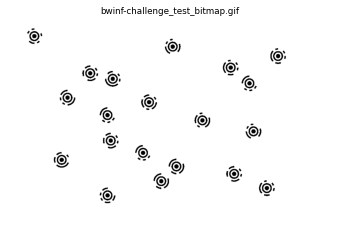

In [ ]:
def lies(dateiname):
    return np.array(Image.open(ORDNER + dateiname).convert('L'))


def zeige(bild, titel='', ergebnis=None, achse=None, schritt=4):
    """Bild verkleinert anzeigen; ergebnis ist eine Liste von Codes (siehe dekodiere), sie werden rot markiert."""
    if achse is None:
        figur, achse = plt.subplots(figsize=(6, 4))
    hoehe, breite = bild.shape
    achse.imshow(bild[::schritt, ::schritt], cmap='gray', vmin=0, vmax=255, extent=(0, breite, hoehe, 0))
    if ergebnis is not None:
        for code in ergebnis:
            achse.plot(code['x'], code['y'], 'r+', markersize=8)
            achse.text(code['x'] + 60, code['y'] - 60, code['zeichen'], color='red', fontsize=9)
    achse.set_title(titel, fontsize=9)
    achse.axis('off')


BITMAP = lies('bwinf-challenge_test_bitmap.gif')
print('Größe (Höhe, Breite):', BITMAP.shape)
print('Helligkeiten:', np.unique(BITMAP).tolist())
zeige(BITMAP, 'bwinf-challenge_test_bitmap.gif')

Im Bild sind 20 Kreiscodes, alle gleich groß. Das Schwarz-Weiß-Bild hat nur die Helligkeiten 0 und 255.

## Schritt 3: Flecken finden

`flecken` bekommt eine Tabelle `dunkel` mit `True` für dunkle Pixel. Alle dunklen Pixel kommen als Tupel `(y, x)` in eine Menge
`offen`. Solange sie nicht leer ist, nehmen wir ein Pixel heraus und sammeln mit Breitensuche alles, was über dunkle Nachbarn (oben,
unten, links, rechts) erreichbar ist. Jedes gefundene Pixel wird sofort aus `offen` entfernt; so wird jedes Pixel nur einmal
angefasst.

`beschreibe` macht aus der Pixelliste eines Flecks ein Dictionary mit der Pixelzahl (`anzahl`), dem Schwerpunkt (`x`, `y`) und den
Koordinaten als numpy-Arrays (`xs`, `ys`), die wir später für den Maßstab und die Ellipse brauchen. Ganz kleine Flecken (unter
`MINDEST` Pixeln, etwa Rauschen) lassen wir weg.

In [ ]:
MINDEST = 30


def flecken(dunkel):
    """Liste der zusammenhängenden dunklen Flecken; jeder Fleck ist eine Liste von Pixeln (y, x)."""
    ys, xs = np.nonzero(dunkel)
    offen = set(zip(ys.tolist(), xs.tolist()))
    alle = []
    while offen:
        start = offen.pop()
        fleck = [start]
        schlange = deque([start])
        while schlange:
            y, x = schlange.popleft()
            for nachbar in ((y - 1, x), (y + 1, x), (y, x - 1), (y, x + 1)):
                if nachbar in offen:
                    offen.remove(nachbar)
                    fleck.append(nachbar)
                    schlange.append(nachbar)
        alle.append(fleck)
    return alle


def beschreibe(fleck):
    pixel = np.array(fleck)
    ys, xs = pixel[:, 0], pixel[:, 1]
    return {'anzahl': len(fleck), 'x': xs.mean(), 'y': ys.mean(), 'xs': xs, 'ys': ys}


def alle_flecken(dunkel):
    liste = []
    for fleck in flecken(dunkel):
        if len(fleck) >= MINDEST:
            liste.append(beschreibe(fleck))
    return liste


dunkel_bitmap = BITMAP < 128
print('dunkle Pixel:', int(dunkel_bitmap.sum()))
FLECKEN_BITMAP = alle_flecken(dunkel_bitmap)
print('Flecken:', len(FLECKEN_BITMAP))
groessen = sorted(f['anzahl'] for f in FLECKEN_BITMAP)
print('kleinste Flecken:', groessen[:5])
print('größte Flecken:', groessen[-5:])

dunkle Pixel: 249171
Flecken: 127
kleinste Flecken: [563, 564, 564, 565, 567]
größte Flecken: [5479, 5479, 5479, 5480, 5483]


Die Breitensuche fasst rund 249.000 dunkle Pixel an und findet 127 Flecken: 20 Scheiben, 20 Ringe und die übrigen sind
Segmente oder Gruppen benachbarter Segmente des äußersten Rings.

## Schritt 4: Mittelpunkte (Teil 1)

Für jeden Fleck als mögliche **Scheibe** suchen wir einen größeren Fleck als **Ring**, dessen Schwerpunkt höchstens 0,3 Scheibenradien
entfernt ist und dessen Fläche 2- bis 3,5-mal so groß ist (genau wären es 2,67). Damit wir jede Scheibe nur mit größeren Flecken
vergleichen, sortieren wir die Flecken vorher nach ihrer Größe (Liste von Tupeln `(anzahl, nummer)`). Der Mittelpunkt des Codes ist der
Schwerpunkt des Rings (er hat mehr Pixel als die Scheibe und ist darum etwas genauer).

Bei 127 Flecken sind das höchstens 127 · 126 / 2 = 8001 Vergleiche, das geht schnell.

In [ ]:
def finde_codes(liste):
    """Paare (Scheibe, Ring) mit fast gleichem Schwerpunkt und passendem Flächenverhältnis."""
    reihenfolge = sorted((f['anzahl'], nummer) for nummer, f in enumerate(liste))
    paare = []
    for i in range(len(reihenfolge)):
        scheibe = liste[reihenfolge[i][1]]
        radius = math.sqrt(scheibe['anzahl'] / math.pi)
        for j in range(i + 1, len(reihenfolge)):
            ring = liste[reihenfolge[j][1]]
            verhaeltnis = ring['anzahl'] / scheibe['anzahl']
            abstand = math.hypot(ring['x'] - scheibe['x'], ring['y'] - scheibe['y'])
            if 2 <= verhaeltnis <= 3.5 and abstand < 0.3 * radius:
                paare.append((scheibe, ring))
                break
    return paare


PAARE_BITMAP = finde_codes(FLECKEN_BITMAP)
print('Kreiscodes:', len(PAARE_BITMAP))
for scheibe, ring in PAARE_BITMAP[:3]:
    print('Scheibe %5d Pixel bei (%.1f, %.1f), Ring %5d Pixel bei (%.1f, %.1f), Verhältnis %.2f' % (
        scheibe['anzahl'], scheibe['x'], scheibe['y'], ring['anzahl'], ring['x'], ring['y'],
        ring['anzahl'] / scheibe['anzahl']))

Kreiscodes: 20
Scheibe  2044 Pixel bei (2671.4, 589.4), Ring  5474 Pixel bei (2671.4, 589.4), Verhältnis 2.68
Scheibe  2045 Pixel bei (1841.8, 1943.7), Ring  5477 Pixel bei (1841.7, 1943.7), Verhältnis 2.68
Scheibe  2046 Pixel bei (1978.8, 339.4), Ring  5479 Pixel bei (1978.7, 339.5), Verhältnis 2.68


Genau 20 Paare, und das Flächenverhältnis liegt sehr nahe an 2,67. Die Mittelpunkte vergleichen wir in Schritt 6 mit den
Lösungshinweisen.

## Schritt 5: Den äußersten Ring ablesen (Teil 2)

**Maßstab.** Für einen Ring mit Innenradius `a` und Außenradius `b` ist der Mittelwert von `d²` (Quadrat des Abstands vom Mittelpunkt)
über alle Pixel des Rings gleich `(a² + b²) / 2`. Mit `a = 2,5w` und `b = 3,5w` sind das `9,25 w²`. So bekommen wir `w` aus allen
Pixeln des Rings auf einmal, das ist genauer als jede einzelne Messung.

**Messen.** `ring_kreis` misst die Helligkeit an 128 Punkten auf dem Kreis mit Radius `faktor · w`, beginnend oben, im Uhrzeigersinn.
Für den äußersten Ring ist `faktor = 5`.

In [ ]:
def mass_w(ring):
    """Ringbreite w aus dem Mittelwert von d² über die Pixel des schwarzen Rings."""
    dx = ring['xs'] - ring['x']
    dy = ring['ys'] - ring['y']
    return math.sqrt((dx * dx + dy * dy).mean() / 9.25)


def wert(bild, x, y):
    """Helligkeit am Punkt (x, y); außerhalb des Bildes weiß."""
    xi, yi = int(round(x)), int(round(y))
    if 0 <= yi < bild.shape[0] and 0 <= xi < bild.shape[1]:
        return int(bild[yi, xi])
    return 255


def ring_kreis(bild, ring, faktor=5, n=128):
    """n Helligkeiten auf dem Kreis mit Radius faktor * w, von oben im Uhrzeigersinn."""
    w = mass_w(ring)
    werte = []
    for k in range(n):
        phi = 2 * math.pi * k / n
        werte.append(wert(bild, ring['x'] + faktor * w * math.sin(phi), ring['y'] - faktor * w * math.cos(phi)))
    return werte


scheibe_k, ring_k = PAARE_BITMAP[0]
print('Code bei (%.0f, %.0f), w = %.2f Pixel' % (ring_k['x'], ring_k['y'], mass_w(ring_k)))
werte_k = ring_kreis(BITMAP, ring_k)
print(''.join('#' if v < 128 else '.' for v in werte_k))

Code bei (2671, 589), w = 17.01 Pixel
#...............#########........########................################........###############################........########


Die Zeile zeigt den äußersten Ring wie einen Strichcode: `#` ist dunkel, `.` hell. Die Läufe sind (fast) immer Vielfache von 8 lang,
aber sie fangen nicht unbedingt bei einem Vielfachen von 8 an, denn der Code kann gedreht sein.

**Bits zuweisen.** `bits_aus` probiert die 8 Verschiebungen `s = 0, …, 7`. Bei Verschiebung `s` besteht Block `j` aus den Messwerten
`s + 8j` bis `s + 8j + 7` (am Ende geht es vorne weiter). Ein Block wird 1, wenn mehr als die Hälfte seiner Werte dunkel ist. Die
**Abweichungen** sind die Messwerte, die nicht zur Mehrheit ihres Blocks passen. Wir nehmen die Verschiebung mit den wenigsten
Abweichungen. Das ist dieselbe Idee wie in den Lösungshinweisen (dort: kleinste Varianz der Blöcke).

In [ ]:
def bits_aus(werte, schwelle, segmente=16):
    """Beste Einteilung in Blöcke: (Abweichungen, Bitfolge)."""
    n = len(werte)
    k = n // segmente                      # Messwerte je Segment
    dunkel = []
    for v in werte:
        dunkel.append(1 if v < schwelle else 0)
    bestes = None
    for s in range(k):
        bits = ''
        abweichungen = 0
        for j in range(segmente):
            einsen = 0
            for t in range(k):
                einsen += dunkel[(s + j * k + t) % n]
            if 2 * einsen > k:
                bits += '1'
            else:
                bits += '0'
            abweichungen += min(einsen, k - einsen)
        if bestes is None or abweichungen < bestes[0]:
            bestes = (abweichungen, bits)
    return bestes


abw_k, bits_k = bits_aus(werte_k, 128)
print('Bits:', bits_k, 'Abweichungen:', abw_k)
print('Normalform:', normalform(bits_k), 'Zeichen:', TABELLE.get(normalform(bits_k), '?'))

Bits: 0010100110111101 Abweichungen: 3
Normalform: 0010100110111101 Zeichen: n


## Schritt 6: Version 1 für das ganze Bild

`dekodiere_v1` setzt alles zusammen: Schwelle 128, Flecken, Paare, Ablesen. Jeder Code wird ein Dictionary mit Mittelpunkt, Bitfolge,
Zeichen (`#`, wenn die Bitfolge nicht in der Tabelle steht) und Abweichungen. Die Codes sortieren wir von oben nach unten, wie die
Lösungshinweise (Liste von Tupeln `(y, nummer)`). `text` macht daraus den Text; `\s` wird ein Leerzeichen.

( 325,  215)  0001001011000101  K    4 Abweichungen
(1979,  339)  0001110001110101  a    3 Abweichungen
(3238,  452)  0010100110111101  n    3 Abweichungen
(2671,  589)  0010100110111101  n    3 Abweichungen
( 993,  657)  0010101110011011  s    3 Abweichungen
(1262,  723)  0010101111110011  t    3 Abweichungen
(2896,  777)  0000010101001111  \s   3 Abweichungen
( 721,  948)  0000111101010111  D    3 Abweichungen
(1696, 1002)  0010111010111011  u    4 Abweichungen
(1200, 1156)  0000010101001111  \s   3 Abweichungen
(2333, 1219)  0001111001011101  d    4 Abweichungen
(2944, 1350)  0001110001110101  a    4 Abweichungen
(1238, 1460)  0010101110011011  s    4 Abweichungen
(1624, 1606)  0000010101001111  \s   3 Abweichungen
( 652, 1689)  0010011111011011  l    4 Abweichungen
(2023, 1769)  0001111011001111  e    2 Abweichungen
(2713, 1857)  0010101110011011  s    4 Abweichungen
(1842, 1944)  0001111011001111  e    2 Abweichungen
(3104, 2027)  0010100110111101  n    4 Abweichungen
(1200, 2113)

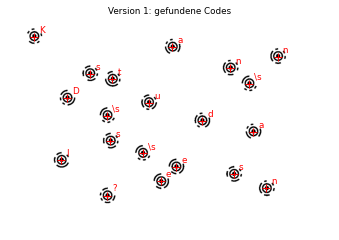

In [ ]:
def code_eintrag(ring, abweichungen, bits):
    return {'x': ring['x'], 'y': ring['y'], 'bits': bits, 'abweichungen': abweichungen,
            'zeichen': TABELLE.get(normalform(bits), '#')}


def von_oben_nach_unten(codes):
    reihenfolge = sorted((c['y'], nummer) for nummer, c in enumerate(codes))
    return [codes[nummer] for y, nummer in reihenfolge]


def dekodiere_v1(bild):
    codes = []
    for scheibe, ring in finde_codes(alle_flecken(bild < 128)):
        abweichungen, bits = bits_aus(ring_kreis(bild, ring), 128)
        codes.append(code_eintrag(ring, abweichungen, bits))
    return von_oben_nach_unten(codes)


def text(codes):
    ergebnis = ''
    for c in codes:
        if c['zeichen'] == '\\s':
            ergebnis += ' '
        else:
            ergebnis += c['zeichen']
    return ergebnis


ERGEBNIS_BITMAP = dekodiere_v1(BITMAP)
for c in ERGEBNIS_BITMAP:
    print('(%4.0f, %4.0f)  %s  %-3s  %d Abweichungen' % (c['x'], c['y'], c['bits'], c['zeichen'], c['abweichungen']))
print('Text:', repr(text(ERGEBNIS_BITMAP)))
zeige(BITMAP, 'Version 1: gefundene Codes', ERGEBNIS_BITMAP)

Der Text heißt **„Kannst Du das lesen?“**, genau wie in den Lösungshinweisen („In allen vorgegebenen Beispielen ist Folgendes kodiert“).
Die Abweichungen (2 bis 4 von 128 Messwerten) liegen an den Grenzen zwischen zwei Segmenten verschiedener Farbe; die
Entscheidung ist also sehr sicher.

**Vergleich mit den Lösungshinweisen.** Die Hinweise geben für das Bild `noise50.jpg` (gleiche Anordnung, aber verrauscht; nicht im
Repo) Mittelpunkte und gelesene Bitfolgen an. Wir vergleichen Abstand und Normalform:

In [ ]:
# (x, y, Bitfolge, Zeichen) aus den Lösungshinweisen, Bild noise50.jpg
HINWEISE = [
    (328, 211, '0001001011000101', 'K'), (1981, 338, '0011101010001110', 'a'), (3240, 451, '1010010100110111', 'n'),
    (2673, 587, '1101001010011011', 'n'), (995, 655, '1001010111001101', 's'), (1264, 721, '1111100110010101', 't'),
    (2898, 776, '0100111100000101', '\\s'), (724, 946, '1010101110000111', 'D'), (1698, 999, '1101100101110101', 'u'),
    (1202, 1155, '0111100000101010', '\\s'), (2334, 1216, '0010111010001111', 'd'), (2945, 1347, '0011101010001110', 'a'),
    (1240, 1458, '1001101100101011', 's'), (1627, 1605, '1111000001010100', '\\s'), (654, 1688, '0100111110110110', 'l'),
    (2025, 1766, '0011110110011110', 'e'), (2715, 1854, '0110010101110011', 's'), (1844, 1941, '0011110001111011', 'e'),
    (3107, 2025, '1101111010010100', 'n'), (1202, 2111, '1011000011011010', '?'),
]

groesster_abstand = 0
gleich = 0
for (hx, hy, hbits, hzeichen), c in zip(HINWEISE, ERGEBNIS_BITMAP):
    groesster_abstand = max(groesster_abstand, math.hypot(hx - c['x'], hy - c['y']))
    if normalform(hbits) == normalform(c['bits']) and hzeichen == c['zeichen']:
        gleich += 1
print('größter Abstand der Mittelpunkte: %.1f Pixel' % groesster_abstand)
print('gleiche Bitfolge (bis auf Drehung) und gleiches Zeichen:', gleich, 'von', len(HINWEISE))

größter Abstand der Mittelpunkte: 4.6 Pixel
gleiche Bitfolge (bis auf Drehung) und gleiches Zeichen: 20 von 20


Alle 20 Codes stimmen überein, die Mittelpunkte liegen höchstens 4,6 Pixel auseinander (bei Codes mit einem Durchmesser von rund
190 Pixeln). Die Bitfolgen der Hinweise sind teils gedreht, denn dort beginnt das Lesen an einer anderen Stelle; die Normalformen sind
gleich.

Und die beiden Graustufenbilder? Für sie reicht Version 1 auch:

In [ ]:
for name in ['bwinf-challenge_test_grey.gif', 'bwinf-challenge_test_grey.jpg']:
    grau_bild = lies(name)
    ergebnis_grau = dekodiere_v1(grau_bild)
    print('%-30s Helligkeiten %3d bis %3d, %2d Codes: %r' % (
        name, grau_bild.min(), grau_bild.max(), len(ergebnis_grau), text(ergebnis_grau)))

bwinf-challenge_test_grey.gif  Helligkeiten  34 bis 255, 20 Codes: 'Kannst Du das lesen?'
bwinf-challenge_test_grey.jpg  Helligkeiten  31 bis 255, 20 Codes: 'Kannst Du das lesen?'


Diese beiden Bilder sind nur das Testbild in Graustufen (Schwarz ist etwa 30 bis 35, Weiß 255) mit leichten JPEG-Störungen. Die echten
Probleme von Fotos fehlen; die bauen wir uns jetzt selbst.

## Schritt 7: Eigene „Fotos“ (Teil 3)

Aus dem Testbild machen wir verschiedene gestörte Bilder. Zuerst wird es grau wie ein Foto (Schwarz 30, Weiß 255). Dann:

- **verzerrt:** eine *affine Abbildung* `(x, y) → (a·x + b·y, c·x + d·y)` staucht das Bild in der Breite auf 55 % und schert es.
  Aus Kreisen werden schiefe Ellipsen, wie bei einem Foto von der Seite. `Image.transform` braucht die Umkehrabbildung (für jedes
  Pixel des neuen Bildes: woher im alten Bild?); die rechnen wir mit der Formel für die Inverse einer 2×2-Matrix aus.
- **gedreht:** das ganze Bild um 37°, damit liegen auch die Segmentgrenzen schräg.
- **Schatten:** Die Helligkeit nimmt nach rechts unten bis auf 15 % ab. Rechts unten ist der weiße Hintergrund dann fast so dunkel wie
  das Schwarz links oben.
- **Rauschen:** Zu jedem Pixel kommt eine Zufallszahl (Normalverteilung mit Standardabweichung 80).
- **unscharf:** Gaußscher Weichzeichner mit Radius 8.
- **alles:** verzerrt, gedreht, Schatten, unscharf und verrauscht zusammen.

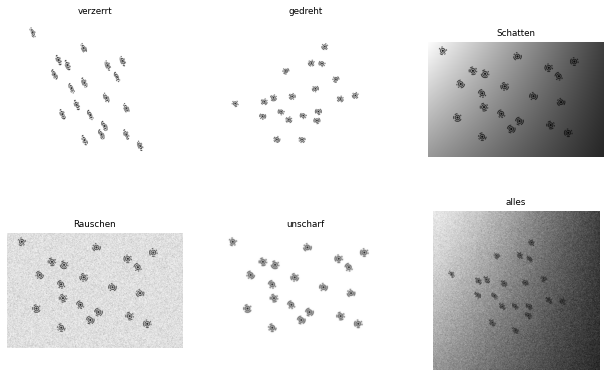

In [ ]:
def als_bild(tabelle):
    return Image.fromarray(np.clip(tabelle, 0, 255).astype(np.uint8))


def verzerre(bild, a, b, c, d):
    """Affine Abbildung (x, y) -> (a x + b y, c x + d y); das neue Bild ist so groß, dass alles hineinpasst."""
    hoehe, breite = bild.shape
    ecken = [(0, 0), (breite, 0), (0, hoehe), (breite, hoehe)]
    xs = [a * x + b * y for x, y in ecken]
    ys = [c * x + d * y for x, y in ecken]
    x0, y0 = min(xs), min(ys)
    det = a * d - b * c                     # Umkehrabbildung: Inverse der Matrix [[a, b], [c, d]]
    ia, ib, ic, id_ = d / det, -b / det, -c / det, a / det
    daten = (ia, ib, ia * x0 + ib * y0, ic, id_, ic * x0 + id_ * y0)
    neu = als_bild(bild).transform((int(max(xs) - x0), int(max(ys) - y0)), Image.AFFINE, daten,
                                   resample=Image.BILINEAR, fillcolor=255)
    return np.array(neu)


def drehe(bild, winkel):
    return np.array(als_bild(bild).rotate(winkel, expand=True, fillcolor=255, resample=Image.BILINEAR))


def schatten(bild):
    hoehe, breite = bild.shape
    faktor = np.linspace(1.0, 0.25, breite)[None, :] * np.linspace(1.0, 0.6, hoehe)[:, None]
    return (bild * faktor).astype(np.uint8)


def rauschen(bild, staerke, saat=1):
    zufall = np.random.default_rng(saat)
    return np.clip(bild + zufall.normal(0, staerke, bild.shape), 0, 255).astype(np.uint8)


def unscharf(bild, radius):
    return np.array(als_bild(bild).filter(ImageFilter.GaussianBlur(radius)))


GRAU = (30 + BITMAP * (225 / 255)).astype(np.uint8)
FOTOS = {
    'verzerrt': verzerre(GRAU, 0.55, 0.25, 0.1, 1.0),
    'gedreht': drehe(GRAU, 37),
    'Schatten': schatten(GRAU),
    'Rauschen': rauschen(GRAU, 80),
    'unscharf': unscharf(GRAU, 8),
    'alles': rauschen(unscharf(schatten(drehe(verzerre(GRAU, 0.7, 0.2, -0.1, 1.0), 20)), 4), 50),
}
figur, achsen = plt.subplots(2, 3, figsize=(11, 6.5))
for achse, name in zip(achsen.flatten(), FOTOS):
    zeige(FOTOS[name], name, achse=achse, schritt=4)

Wie weit kommt Version 1? Bei „Schatten“ und „alles“ lassen wir sie nicht laufen: Mit der festen Schwelle 128 ist dort ein großer Teil
des Hintergrunds „dunkel“, und die Breitensuche müsste Millionen Pixel anfassen. Wir zählen nur die dunklen Pixel.

In [ ]:
for name in ['verzerrt', 'gedreht', 'Rauschen', 'unscharf']:
    ergebnis_v1 = dekodiere_v1(FOTOS[name])
    print('%-9s %2d Codes: %r' % (name, len(ergebnis_v1), text(ergebnis_v1)))
for name in ['Schatten', 'alles']:
    print('%-9s dunkle Pixel bei Schwelle 128: %d von %d' % (name, (FOTOS[name] < 128).sum(), FOTOS[name].size))

verzerrt  20 Codes: '##NULLNULL####NULL##NULLNULL#NULL##NULLNULL#'
gedreht   20 Codes: 'nn aadnutssKe  Dsel?'
Rauschen  20 Codes: 'Kan#st ## das lesen?'
unscharf  20 Codes: 'Kannst Du das lesen?'
Schatten  dunkle Pixel bei Schwelle 128: 5335238 von 9975095
alles     dunkle Pixel bei Schwelle 128: 8190426 von 15721760


- **verzerrt:** Die Mittelpunkte findet Version 1 (Schwerpunkte und Flächenverhältnis bleiben bei einer affinen Abbildung erhalten),
  aber auf dem Kreis mit Radius 5w liegen die Messpunkte teils neben dem äußersten Ring: kein einziges Zeichen ist richtig.
- **gedreht:** Alle Zeichen stimmen. Die Reihenfolge von oben nach unten ist im gedrehten Bild natürlich eine andere.
- **Rauschen:** Drei Codes ergeben `#` (Bitfolge nicht in der Tabelle): Verrauschte Messpunkte kippen einzelne Blöcke.
- **unscharf:** 20 von 20 richtig. Die Ränder werden grau, die Flecken schrumpfen bei der Schwelle 128 etwas. Weil wir
  den Maßstab aus allen Pixeln des Rings bestimmen (Innenrand nach innen, Außenrand nach außen verschoben), stört das kaum.
- **Schatten:** 53 % des Bildes sind „dunkel“, darin geht jeder Code unter.

## Schritt 8: Version 2 – robust gegen Störungen

Vier Änderungen:

1. **Glätten.** Ein Gaußscher Weichzeichner mit Radius 2 mittelt das Rauschen weg. Er darf nicht zu stark sein, sonst verschwimmen
   kleine Codes (siehe die Grenzen unten).
2. **Schwelle relativ zur Umgebung.** `BoxBlur(80)` bildet für jedes Pixel den Mittelwert eines Quadrats mit 161 Pixeln Seitenlänge.
   Dunkel ist ein Pixel, wenn es weniger als 70 % dieses Mittelwerts hat. Im Schatten sind Pixel und Umgebung gleichermaßen dunkler,
   das Verhältnis bleibt gleich. (Im Inneren eines Codes ist die Umgebung dunkler, etwa halb so hell wie der Hintergrund; 70 % davon
   liegen dann immer noch deutlich über dem Schwarz des Codes.)
3. **Ellipse statt Kreis.** Für einen Kreis waren die Mittelwerte von `dx²` und `dy²` über die Ringpixel beide gleich `4,625 w²`
   (die Hälfte von `9,25 w²`) und der Mittelwert von `dx·dy` gleich 0. Bei einer Ellipse fassen wir die drei Mittelwerte zur
   **Kovarianzmatrix** `[[mittel(dx²), mittel(dx·dy)], [mittel(dx·dy), mittel(dy²)]]` zusammen. `np.linalg.eigh` liefert ihre
   **Eigenwerte** `λ1, λ2` und **Eigenvektoren** `v1, v2`: Die Eigenvektoren zeigen in Richtung der beiden Ellipsenachsen, und in
   Richtung `v1` ist der Ring um den Faktor `w1 = √(λ1 / 4,625)` gestreckt (genauso `w2`). Der Punkt zum Winkel `φ` auf dem
   äußersten Ring ist dann `Mittelpunkt + 5·(w1·cos φ·v1 + w2·sin φ·v2)`. Für einen Kreis ist das wieder Schritt 5.
   Damit wir im Uhrzeigersinn laufen, nehmen wir als `v2` den um 90° im Uhrzeigersinn gedrehten Vektor `v1` (im Bild mit y nach
   unten: `(x, y) → (−y, x)`). Wo wir anfangen, ist egal, das erledigt die Normalform. Gleich große Winkelschritte in `φ` sind
   gleich große Schritte *auf dem Code*; die Segmente sind also auch auf einer Ellipse 8 Messwerte breit (die Lösungshinweise
   behandeln das in Abbildung 19).
4. **Bitschwelle aus dem Code selbst.** Wir messen auch auf dem schwarzen Ring (Faktor 3) und auf den beiden weißen Ringen (Faktor 2
   und 4). Die Schwelle liegt in der Mitte zwischen dem Median der schwarzen und dem Median der weißen Messwerte. So hängt die
   Entscheidung nur von der Umgebung des Codes ab (das verlangen auch die Bewertungskriterien bei Schatten).

w (Kreis) = 14.1, Achsen der Ellipse: 8.4 und 18.1 Pixel


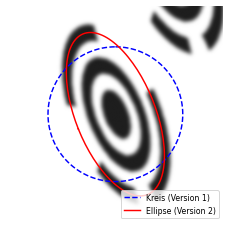

In [ ]:
def ellipse(ring):
    """Mittelpunkt und die beiden gestreckten Achsen (w1 * v1, w2 * v2) des Codes."""
    dx = ring['xs'] - ring['x']
    dy = ring['ys'] - ring['y']
    kovarianz = np.array([[(dx * dx).mean(), (dx * dy).mean()],
                          [(dx * dy).mean(), (dy * dy).mean()]])
    eigenwerte, eigenvektoren = np.linalg.eigh(kovarianz)
    v1 = eigenvektoren[:, 0]
    v2 = np.array([-v1[1], v1[0]])         # v1 um 90 Grad im Uhrzeigersinn gedreht (y zeigt nach unten)
    w1 = math.sqrt(eigenwerte[0] / 4.625)
    w2 = math.sqrt(eigenwerte[1] / 4.625)
    return ring['x'], ring['y'], w1 * v1, w2 * v2


def ring_ellipse(bild, ring, faktor=5, n=128):
    """Wie ring_kreis, aber auf der Ellipse durch den Code."""
    cx, cy, achse1, achse2 = ellipse(ring)
    werte = []
    for k in range(n):
        phi = 2 * math.pi * k / n
        x = cx + faktor * (math.cos(phi) * achse1[0] + math.sin(phi) * achse2[0])
        y = cy + faktor * (math.cos(phi) * achse1[1] + math.sin(phi) * achse2[1])
        werte.append(wert(bild, x, y))
    return werte


def glaette(bild, radius):
    if radius == 0:
        return bild
    return np.array(Image.fromarray(bild).filter(ImageFilter.GaussianBlur(radius)))


def dunkel_relativ(bild):
    umgebung = np.array(Image.fromarray(bild).filter(ImageFilter.BoxBlur(80)))
    return bild < 0.7 * umgebung


def dekodiere_v2(bild, radius=2):
    bild = glaette(bild, radius)
    codes = []
    for scheibe, ring in finde_codes(alle_flecken(dunkel_relativ(bild))):
        schwarz = np.median(ring_ellipse(bild, ring, 3))
        weiss = np.median(ring_ellipse(bild, ring, 2) + ring_ellipse(bild, ring, 4))
        abweichungen, bits = bits_aus(ring_ellipse(bild, ring), (schwarz + weiss) / 2)
        codes.append(code_eintrag(ring, abweichungen, bits))
    return von_oben_nach_unten(codes)


# Ein Code aus dem verzerrten Bild: Messpunkte von Version 1 (Kreis) und Version 2 (Ellipse)
bild_vz = glaette(FOTOS['verzerrt'], 2)
paar_vz = finde_codes(alle_flecken(dunkel_relativ(bild_vz)))[0][1]
cx_vz, cy_vz, a1_vz, a2_vz = ellipse(paar_vz)
w_vz = mass_w(paar_vz)
figur, achse = plt.subplots(figsize=(4, 4))
r_vz = int(8 * w_vz)
achse.imshow(bild_vz[int(cy_vz) - r_vz:int(cy_vz) + r_vz, int(cx_vz) - r_vz:int(cx_vz) + r_vz], cmap='gray', vmin=0, vmax=255,
             extent=(int(cx_vz) - r_vz, int(cx_vz) + r_vz, int(cy_vz) + r_vz, int(cy_vz) - r_vz))
winkel = np.linspace(0, 2 * math.pi, 129)
achse.plot(cx_vz + 5 * w_vz * np.sin(winkel), cy_vz - 5 * w_vz * np.cos(winkel), 'b--', label='Kreis (Version 1)')
achse.plot(cx_vz + 5 * (np.cos(winkel) * a1_vz[0] + np.sin(winkel) * a2_vz[0]),
           cy_vz + 5 * (np.cos(winkel) * a1_vz[1] + np.sin(winkel) * a2_vz[1]), 'r-', label='Ellipse (Version 2)')
achse.legend(fontsize=8, loc='lower right')
achse.axis('off')
print('w (Kreis) = %.1f, Achsen der Ellipse: %.1f und %.1f Pixel' % (
    w_vz, math.hypot(a1_vz[0], a1_vz[1]), math.hypot(a2_vz[0], a2_vz[1])))

Der blaue Kreis von Version 1 läuft teils durch den weißen Ring und über den Code hinaus, die rote Ellipse liegt genau auf dem
äußersten Ring.

## Schritt 9: Alle Beispiele

Version 2 auf den drei vorgegebenen Bildern und unseren sechs „Fotos“. Bei den gedrehten und gescherten Bildern ist die Reihenfolge von
oben nach unten eine andere; dort vergleichen wir nur, ob dieselben Zeichen vorkommen (`Counter` zählt, wie oft jedes Zeichen vorkommt).

bitmap.gif 20 Codes, Abweichungen bis  2: 'Kannst Du das lesen?' richtig
grey.gif   20 Codes, Abweichungen bis  5: 'Kannst Du das lesen?' richtig
grey.jpg   20 Codes, Abweichungen bis  4: 'Kannst Du das lesen?' richtig
verzerrt   20 Codes, Abweichungen bis  1: 'KasntnD u dsal ese?n' richtige Zeichen
gedreht    20 Codes, Abweichungen bis  4: 'nn aadnutssKe  Dsel?' richtige Zeichen
Schatten   20 Codes, Abweichungen bis  1: 'Kannst Du das lesen?' richtig
Rauschen   20 Codes, Abweichungen bis  5: 'Kannst Du das lesen?' richtig
unscharf   20 Codes, Abweichungen bis 14: 'Kannst Du das lesen?' richtig
alles      20 Codes, Abweichungen bis  5: 'nna KatsduD sn seel?' richtige Zeichen


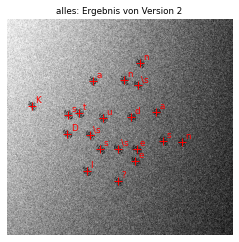

In [ ]:
SOLL = 'Kannst Du das lesen?'
BILDER = {'bitmap.gif': BITMAP, 'grey.gif': lies('bwinf-challenge_test_grey.gif'),
          'grey.jpg': lies('bwinf-challenge_test_grey.jpg')}
BILDER.update(FOTOS)
ERGEBNISSE_V2 = {}
for name in BILDER:
    ergebnis_v2 = dekodiere_v2(BILDER[name])
    ERGEBNISSE_V2[name] = ergebnis_v2
    if text(ergebnis_v2) == SOLL:
        urteil = 'richtig'
    elif Counter(text(ergebnis_v2)) == Counter(SOLL):
        urteil = 'richtige Zeichen'
    else:
        urteil = 'FEHLER'
    print('%-10s %2d Codes, Abweichungen bis %2d: %-22r %s' % (
        name, len(ergebnis_v2), max(c['abweichungen'] for c in ergebnis_v2), text(ergebnis_v2), urteil))
zeige(BILDER['alles'], 'alles: Ergebnis von Version 2', ERGEBNISSE_V2['alles'], schritt=6)

Version 2 liest in allen neun Bildern alle 20 Zeichen richtig, auch im Bild mit allen Störungen zugleich. Die Abweichungen zählen
die Messwerte im ganzen Ring, die nicht zur Mehrheit ihres Blocks passen; ein Bit kippt erst, wenn in einem einzigen Block mindestens 4
der 8 Werte falsch sind. Am meisten Abweichungen hat das unscharfe Bild (bis zu 14 von 128, dort sind die Segmentgrenzen
verwaschen), in den anderen Bildern sind es höchstens 5.

**Grenzen.** Jedes Verfahren hat sie; wir haben einige gesucht:

In [ ]:
GRENZEN = {
    'Rauschen 200': (rauschen(GRAU, 200), 2),
    'unscharf 12': (unscharf(GRAU, 12), 2),
    'gestaucht auf 25 %': (verzerre(GRAU, 0.25, 0, 0, 1), 2),
    'verkleinert auf 1/6': (np.array(als_bild(GRAU).reduce(6)), 2),
    'verkleinert, ohne Glätten': (np.array(als_bild(GRAU).reduce(6)), 0),
}
for name in GRENZEN:
    bild_g, radius_g = GRENZEN[name]
    ergebnis_g = dekodiere_v2(bild_g, radius_g)
    print('%-26s %4d x %4d Pixel, %2d Codes gefunden, Text %r' % (name, bild_g.shape[1], bild_g.shape[0],
                                                                len(ergebnis_g), text(ergebnis_g)))

Rauschen 200               3895 x 2561 Pixel, 20 Codes gefunden, Text 'Kannst Du das lesen?'
unscharf 12                3895 x 2561 Pixel,  0 Codes gefunden, Text ''
gestaucht auf 25 %          973 x 2561 Pixel, 20 Codes gefunden, Text 'Kannst Du das lesen?'
verkleinert auf 1/6         650 x  427 Pixel,  0 Codes gefunden, Text ''
verkleinert, ohne Glätten   650 x  427 Pixel, 20 Codes gefunden, Text 'Kannst Du das lesen?'


- **Rauschen mit Standardabweichung 200** (mehr Rauschen als Bild) schafft Version 2 noch: Das Glätten mittelt über viele Pixel.
- **Unschärfe mit Radius 12** ist zu viel: Die Ringe sind nur 17 Pixel breit, schwarze und weiße Ringe verschwimmen zu fast
  demselben Grau (beim ersten Code etwa 151 in der Mitte des weißen und 137 in der Mitte des schwarzen Rings). Der schwarze Ring
  wird nicht mehr als dunkel erkannt, nur die Scheiben bleiben übrig, und ohne Ring gibt es kein Paar.
- **Auf ein Viertel der Breite gestaucht** ist kein Problem, die Ellipse passt sich an.
- **Verkleinert auf 1/6** ist die Ringbreite nur noch knapp 3 Pixel. Dann zerstört schon das Glätten mit Radius 2 die Codes, ohne
  Glätten werden alle 20 gelesen. Genau davor warnen die Lösungshinweise: Die Glättung darf kleine Kreiscodes nicht kaputt machen.
  Ein besseres Programm würde den Radius an die Größe der Codes anpassen (erst ohne Glätten die Flecken suchen, dann passend glätten).

Die echten Fotos der BWINF-Webseite haben weitere Schwierigkeiten: perspektivische Verzerrung (dann ist ein Code nur ungefähr eine
Ellipse), Knicke im Papier, ungleichmäßiges Licht, Codes, die am Bildrand nur zum Viertel zu sehen sind. Die Lösungshinweise lesen in
`cam8.jpg` und `camB.jpg` alle 20 Zeichen. Wir haben die Fotos hier nicht; wer sie aus `kreiscode.zip` herunterlädt, kann es mit
`dekodiere_v2(np.array(Image.open('bwinf-challenge-test-cam8.jpg').convert('L')))` ausprobieren.

## Für Neugierige

**Eigene Kreiscodes malen.** Mit der Tabelle können wir auch selbst Text in Kreiscodes schreiben. `male_code` färbt für jedes Pixel in
einem Quadrat um den Mittelpunkt: Es berechnet Abstand `d` (in Ringbreiten) und Winkel (von oben im Uhrzeigersinn, mit `math.atan2`,
hier für ganze numpy-Tabellen `np.arctan2`) und daraus, in welchem Ring und welchem Segment das Pixel liegt. Jeder Code bekommt eine
zufällige Drehung. Die Zeichen stehen von oben nach unten, damit die Leserichtung wieder stimmt.

sauber: 'Hallo BwInf!'
gestört: 'Hallo BwInf!'


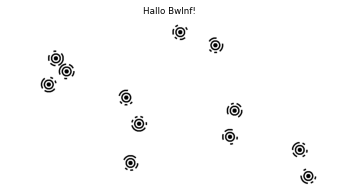

In [ ]:
ZEICHEN_ZU_BITS = {}
for nf in TABELLE:
    ZEICHEN_ZU_BITS[TABELLE[nf]] = nf


def male_code(bild, cx, cy, w, bits, drehung):
    groesse = int(5.5 * w) + 2
    ys, xs = np.mgrid[cy - groesse:cy + groesse + 1, cx - groesse:cx + groesse + 1]
    d = np.hypot(xs - cx, ys - cy) / w
    winkel = (np.arctan2(xs - cx, cy - ys) - drehung) % (2 * math.pi)       # von oben im Uhrzeigersinn
    segment = (winkel / (2 * math.pi) * 16).astype(int) % 16
    bit_ist_eins = np.array([b == '1' for b in bits])[segment]
    schwarz = (d < 1.5) | ((d >= 2.5) & (d < 3.5)) | ((d >= 4.5) & (d < 5.5) & bit_ist_eins)
    ausschnitt = bild[cy - groesse:cy + groesse + 1, cx - groesse:cx + groesse + 1]
    ausschnitt[schwarz] = 0


def schreibe(nachricht, w=12, saat=7):
    zufall = random.Random(saat)
    abstand = int(9 * w)
    bild = np.full(((len(nachricht) + 1) * abstand, 25 * abstand), 255, dtype=np.uint8)
    for i, zeichen in enumerate(nachricht):
        if zeichen == ' ':
            zeichen = '\\s'
        cx = zufall.randint(abstand, 24 * abstand)
        cy = (i + 1) * abstand
        male_code(bild, cx, cy, w, ZEICHEN_ZU_BITS[zeichen], zufall.uniform(0, 2 * math.pi))
    return bild


EIGENES = schreibe('Hallo BwInf!')
zeige(EIGENES, 'Hallo BwInf!', schritt=2)
EIGENES_FOTO = rauschen(unscharf(schatten(verzerre(EIGENES, 0.8, -0.3, 0, 1.0)), 2), 60)
print('sauber:', repr(text(dekodiere_v2(EIGENES))))
print('gestört:', repr(text(dekodiere_v2(EIGENES_FOTO))))

Die Codes liegen hier eng (der Abstand der Zeilen ist nur 9w, ein Code ist 11w breit) und sind kleiner als im Testbild (w = 12).
Trotzdem findet Version 2 alle, im sauberen und im gestörten Bild.

**Laufzeit.** Die Breitensuche fasst jedes dunkle Pixel einmal an, Glätten und `BoxBlur` brauchen konstant viel Arbeit je Pixel. Das
Paaren der Flecken ist quadratisch in der Zahl der Flecken, die aber klein ist (rund 130). Alles zusammen ist linear in der Zahl der
Pixel, wie es die Bewertungskriterien erwarten. Die Schablonensuche der Lösungshinweise ist ebenfalls linear, macht aber pro Pixel
viel mehr Arbeit (dort rund 570 Millionen Schablonentests für ein Bild).

**Fehler erkennen.** Wir haben nachgezählt: Keine zwei Einträge der Tabelle unterscheiden sich (bis auf Drehung) in nur einem Bit.
Kippt beim Lesen genau ein Bit, steht die Bitfolge also sicher nicht in der Tabelle, und das Programm zeigt `#` statt eines falschen
Zeichens. Die Lösungshinweise schlagen vor, dann einzelne Bits umzudrehen; das kann aber auf mehrere Einträge führen. Man könnte stattdessen
nur das unsicherste Bit umdrehen (den Block, dessen Mehrheit am knappsten war); das haben wir nicht eingebaut.

In [ ]:
abstand_eins = 0
for nf in TABELLE:
    for i in range(16):
        gekippt = nf[:i] + str(1 - int(nf[i])) + nf[i + 1:]
        if normalform(gekippt) in TABELLE:
            abstand_eins += 1
print('Paare von Einträgen, die sich in einem Bit unterscheiden:', abstand_eins)

Paare von Einträgen, die sich in einem Bit unterscheiden: 0


**Andere Bibliotheken.** Die Breitensuche über alle Pixel erledigt `scipy.ndimage.label` in einem Aufruf (viel schneller), und
Bibliotheken wie OpenCV können Kreise und Ellipsen direkt finden (`HoughCircles`, `fitEllipse`). Für den Wettbewerb muss man dann
erklären, was diese Funktionen tun und wie ihre Parameter gewählt sind.

**Und MiniZinc?** Diesmal nicht. Die Aufgabe ist Bildverarbeitung mit Millionen Pixeln und Kommazahlen (Schwerpunkte, Ellipsen,
Helligkeiten). Das einzige kleine Suchproblem, die Wahl der Segmentgrenzen (8 Möglichkeiten) und das Nachschlagen in der Tabelle
(128 Einträge mal 16 Drehungen), lösen wir durch Ausprobieren in Sekundenbruchteilen; ein Solver brächte nichts.